In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from plotnine import *
import numpy as np

In [2]:
# Import both datasets

# SEQ = "./metadata/sequence_metadata/NCBI-BVBRC-GIS_ha_detectionsgeodata.tsv"
SEQ = "./metadata/sequence_metadata/NCBI-BVBRC_ha_detectionsgeodata.tsv"
ha_seq = pd.read_csv(SEQ, sep = "\t")

# US_DETECT = "./metadata/detections_data/HPAI Detections in Wild Birds (dwnld 2025-01-31).csv"
# us_detections = pd.read_csv(US_DETECT, sep = ",")

# CAN_DETECT = "./metadata/detections_data/HPAI_IAHP_Wildlife_Faune__file_fichie.csv"
# can_detections = pd.read_csv(CAN_DETECT, sep = ",")

ALL_DETECT = "./metadata/detections_data/combinedNAm_detections_2021-2025.csv"
concat_detections = pd.read_csv(ALL_DETECT, sep = ",")
concat_detections["year_month"] = concat_detections["Collection Date"].str.split("-", expand = True)[0] + "/" + concat_detections["Collection Date"].str.split("-", expand = True)[1]

In [4]:
print("Number of sequences from North American wild birds", len(ha_seq))
print("Number of US detections:", len(us_detections))
print("Number of Canadian detections:", len(can_detections))

Number of sequences from North American wild birds 6737
Number of US detections: 11065
Number of Canadian detections: 2858


In [7]:
# Sequencing dataset manipulation

# Subset to just wild birds
# ha_seq_wild = ha_seq[ha_seq["domesticstatus_combined"] == "wild"]
ha_seq_wild = ha_seq[ha_seq["ncbibvbrc_domesticstatus"] == "wild"]

# Make a year_month column
ha_seq_wild_yearmonth = ha_seq_wild.copy()
ha_seq_wild_yearmonth["year_only"] = ha_seq_wild_yearmonth["year_only"].astype(str).str.replace(".0", "")
ha_seq_wild_yearmonth["month_only"] = ha_seq_wild_yearmonth["month_only"].astype(str).str.replace(".0", "").str.zfill(2)
ha_seq_wild_yearmonth["year_month"] = ha_seq_wild_yearmonth[["year_only", "month_only"]].agg("/".join, axis = 1).astype(str).replace(["nan", "nan/nan"], np.nan) #aggregate year and month and replace unknowns with NaN
ha_seq_wild_yearmonth = ha_seq_wild_yearmonth.dropna(subset=["year_month"]) # Drop NaN

# Subset dataframe, and bin by year_month
# columns = ["strain", "bird_order", "year_month", "division"]
columns = ["strain", "ncbibvbrc_order", "year_month", "ncbibvbrc_division"]
ha_seq_final = ha_seq_wild_yearmonth.loc[0:, columns] # Filter

ha_seq_final["type"] = "sequences" # add a "sequences" column

ha_seq_final = (ha_seq_final.sort_values('year_month').reset_index(drop=True)) # sort the dataframe?

In [6]:
print("Number of sequences from North American wild birds - updated:", len(ha_seq_final))

Number of sequences from North American wild birds - updated: 5866


In [7]:
# US Detections dataset manipulation

# Add year_month column
us_detections["year_month"] = us_detections["Collection Date"].str.split("/", expand = True)[2] + "/" + us_detections["Collection Date"].str.split("/", expand = True)[0].str.zfill(2)
us_detections["year_month"] = us_detections["year_month"].replace(["nan", "nan/nan", r"2021/\d{2}"], value=np.nan, regex=True)
us_detections = us_detections.dropna(subset=["year_month"])
us_detections["year_month"] = us_detections["year_month"].astype(str)

# Alter host names (in a new column) to match the full host list
us_detections["species_name_altered"] = us_detections["Bird Species"].copy()
us_detections["species_name_altered"] = us_detections["species_name_altered"].str.strip()
us_detections["species_name_altered"] = us_detections["species_name_altered"].str.lower()
us_detections["species_name_altered"] = us_detections["species_name_altered"].str.replace("-", "")
us_detections["species_name_altered"] = us_detections["species_name_altered"].str.replace(" ", "")
us_detections["species_name_altered"] = us_detections["species_name_altered"].str.replace("'", "")
us_detections["species_name_altered"] = us_detections["species_name_altered"].str.replace("(unidentified)", "")

# Next, read in the host-to-order list as a dictionary 
host_to_order = pd.read_csv("./metadata/helpful_lists/NAm_host_list_order-domesticstat.csv", sep = ',', encoding='latin-1')
host_to_order_dict = host_to_order.set_index("strain_host").to_dict(orient="index")

# Finally, use this dictionary to add an "order" column to the detections
us_detections["host_order"] = us_detections["species_name_altered"].map(lambda strain_host: host_to_order_dict.get(strain_host, {}).get("order"))

# Subset to year month and detections_host_order
columns = ["State", "host_order", "year_month"]
us_detections_final = us_detections.loc[0:, columns] # Filter

us_detections_final["type"] = "us_cases"

us_detections_final = (us_detections_final.sort_values('year_month').reset_index(drop=True))

In [8]:
# Canadian Detections dataset manipulation

can_detections["year_month"] = can_detections["Collection Date"].str.split(".", expand = True)[0] + "/" + can_detections["Collection Date"].str.split(".", expand = True)[1]
can_detections["year_month"] = can_detections["year_month"].astype(str).replace(["nan", "nan/nan", r"2021/\d{2}"], value=np.nan, regex=True)
can_detections = can_detections.dropna(subset=["year_month"])

# Alter host names (in a new column) to match the full host list
can_detections["species_name_altered"] = can_detections["Common Name"].copy()
can_detections["species_name_altered"] = can_detections["species_name_altered"].str.strip()
can_detections["species_name_altered"] = can_detections["species_name_altered"].str.lower()
can_detections["species_name_altered"] = can_detections["species_name_altered"].str.replace("-", "")
can_detections["species_name_altered"] = can_detections["species_name_altered"].str.replace(" ", "")
can_detections["species_name_altered"] = can_detections["species_name_altered"].str.replace("'", "")

# Limit to just Avian
can_detections_avian = can_detections[can_detections["Animal Class"] == "Avian"].copy()

# Limit to just before 2025
year_str = can_detections_avian["Collection Date"].str.split(".", expand = True)[0]
can_detections_avian_years = can_detections_avian[year_str < "2025"].copy()

# Next, read in the host-to-order list as a dictionary 
host_to_order = pd.read_csv("./metadata/helpful_lists/NAm_host_list_order-domesticstat.csv", sep = ',', encoding='latin-1')
host_to_order_dict = host_to_order.set_index("strain_host").to_dict(orient="index")

# Finally, use this dictionary to add an "order" column to the detections
can_detections_avian_years["host_order"] = can_detections_avian_years["species_name_altered"].map(lambda strain_host: host_to_order_dict.get(strain_host, {}).get("order"))

# Subset to year month and detections_host_order
columns = ["Province", "host_order", "year_month"]
can_detections_avian_final = can_detections_avian_years.loc[0:, columns] # Filter

can_detections_avian_final["type"] = "can_cases"

can_detections_avian_final = (can_detections_avian_final.sort_values('year_month').reset_index(drop=True))

In [7]:
# Merge dataframes on year_month, inclusive of both

concat_detections = pd.concat([us_detections_final, can_detections_avian_final], axis = 0, join = "outer")

print(concat_detections["type"].value_counts())
print(concat_detections["year_month"].value_counts())

# concat_df["dataset"] = concat_df["from_1"].fillna(concat_df["from_2"])

KeyError: 'type'

In [10]:
weird_yrmon = ["2022/03", "2022/04", "2022/05", "2022/06", "2022/07", "2022/08", "2022/09", "2022/10"]

weird_period = concat_df[concat_df["year_month"].isin(weird_yrmon)]
print(weird_period["type"].value_counts())

NameError: name 'concat_df' is not defined

In [9]:
# Issue: not all year_month have sequences
# Solution: add count = 0 for months without anything

# 1. Convert string year_month to datetime
ha_seq_final['year_month'] = pd.to_datetime(ha_seq_final['year_month'],format='%Y/%m')

# 2. Group and count
sequence_counts = ha_seq_final.groupby('year_month').size()

# 3. Create full monthly index
full_month_index = pd.date_range(
    start=sequence_counts.index.min(),
    end=sequence_counts.index.max(),
    freq='MS'  # Month start
)

# 4. Reindex to include missing months with 0
sequence_counts = (sequence_counts.reindex(full_month_index, fill_value=0).sort_index())

sequence_counts.index = sequence_counts.index.strftime('%Y/%m')

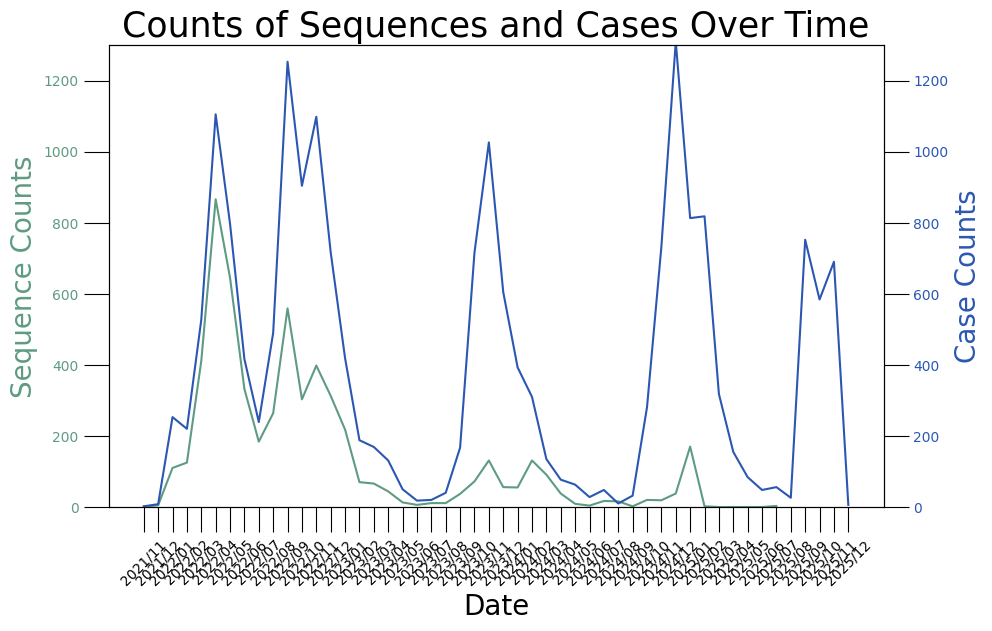

In [14]:
# Plot

# Ensure 'year_month' is sorted for plotting

# concat_detections_sorted = concat_detections.sort_values("year_month")
# concat_detections_sorted = (
#     concat_detections
#     .assign(year_month_dt=pd.to_datetime(concat_detections["year_month"], format="%Y/%m"))
#     .sort_values("year_month_dt")
#     .drop(columns="year_month_dt")
# )

# sequence_counts = ha_seq_final.groupby('year_month').size().sort_index()
# sequence_counts = ha_seq_final_short.groupby('year_month').size().sort_index()
#print(sequence_counts)

detections_counts = concat_detections.groupby('year_month').size().sort_index()
# detections_counts = concat_detections_short.groupby('year_month').size().sort_index()
# print(detections_counts)

#print(type(sequence_counts.index[0]))
# print(type(detections_counts.index[0]))

# Custom colors (hex codes)
seq_color = "#5E9B82"  
detections_color = "#2B57B3"  

# Plot
fig, ax1 = plt.subplots(figsize=(10, 6))

# X-axis label
ax1.set_xlabel('Date', size = 20)
ax1.tick_params(axis='x', labelcolor="#000000", size = 18, labelrotation=45) 

# First axis for bird_order counts
ax1.plot(sequence_counts.index, sequence_counts.values, color = seq_color, label='Sequences')
ax1.set_ylim([0, 1300])
ax1.set_ylabel('Sequence Counts', color=seq_color, size = 20)
ax1.tick_params(axis='y', labelcolor=seq_color, size = 18)

# Second axis for host_order counts
ax2 = ax1.twinx()
ax2.plot(detections_counts.index, detections_counts.values, color = detections_color, label='Cases')
ax2.set_ylim([0, 1300])
ax2.set_ylabel('Case Counts', color=detections_color, size = 20)
ax2.tick_params(axis='y', labelcolor=detections_color, size = 18)

plt.title('Counts of Sequences and Cases Over Time', size = 25)
# fig.autofmt_xdate()  # Improve x-axis date formatting if applicable
plt.show()

In [13]:
plt.savefig("./metadata/exploratory_data_analysis/sequences_vs_cases_updated-2026-01-20.png", dpi=300, bbox_inches='tight')

<Figure size 640x480 with 0 Axes>